# 03 — Scenario engineering

## What are we trying to solve?

Features such as distance, speed, direction, pressure, and visibility are not possession labels. They become useful when combined into a football situation that explains what may happen next. This notebook keeps that reasoning under a small set of cases instead of presenting a gallery of repeated plots.

A scenario is evidence context. It can delay a decision, lower confidence, or open a transition interval; it does not create `H` or `A` by itself.

## Case dictionary

| Case | Observable evidence | Football interpretation | Downstream use |
|---|---|---|---|
| Missing ball | endpoint continuity, direction, player arrival, pressure | the ball may be hidden, travelling, or out of play | compare path hypotheses; preserve uncertainty when receivers remain ambiguous |
| Short touch / handoff | proximity change, contact-like speed change, forward persistence | a touch may or may not change ownership | open a local H↔A hypothesis; require control before switching |
| Long-ball candidate | kick departure, accumulated distance before the control/touch boundary, coherent flight | launch team has continuity during flight, but landing ownership is unresolved | hold the prior state until landing/control evidence |
| Contested | both teams arrive or converge without stable control | neither team can yet own the ball confidently | retain `CONTESTED`/`NO_SWITCH` evidence |
| Restart | tag context, near-stationary phase, activation, first controlled touch | dead ball is ending but play is not necessarily live at the first appearance | keep `D` until activation plus control evidence |

In [1]:
# Build the canonical evidence table once. Public labels are audit-only.
from pathlib import Path
import sys
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import find_peaks

ROOT = Path.cwd().resolve()
while not (ROOT / 'possession_lab').exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

from possession_lab.baseline_pipeline import ClosestTeamRuleModel, slot_team_map
from possession_lab.calculations.features import build_engineered_features
from possession_lab.calculations.plotting import _configure_match_clock_axis, plot_timeline_window, select_evidence_window
from possession_lab.calculations.scenario_evidence import build_scenario_evidence
from possession_lab.temporal_rules import load_rules
from games import asset_paths

rules = load_rules()
model = ClosestTeamRuleModel()
features = build_engineered_features(model=model, rules=rules)
team_by_slot = slot_team_map(asset_paths(model.game, model.data_dir, source='tactical')['atd_meta'])
gt_path = ROOT / 'evaluation' / 'gt' / 'BAR-ATH_possession_gt_public.csv'
gt_by_frame = pd.read_csv(gt_path).set_index('frame')['label'] if gt_path.exists() else None
insight_path = ROOT / 'data' / 'first_half_gt.csv'
insight_gt_by_frame = pd.read_csv(insight_path).set_index('frame')['label'] if insight_path.exists() else gt_by_frame

case_windows = {
    'case_a_missing_ball': select_evidence_window(features, kind='missing_ball', context_frames=50),
    'case_b_candidate_transition': select_evidence_window(features, kind='transition', context_frames=75),
}
print('feature table:', features.shape)
print(features['scenario_context'].value_counts(dropna=False).to_string())

feature table: (199319, 664)
scenario_context
OCCLUDED                 71724
BALL_IN_FLIGHT           27831
RESTART_LIVE_BOUNDARY    22378
DEAD                     17558
UNKNOWN                  16051
CONTROLLED               15781
CONTESTED                10455
PRESSURED_CONTROL        10188
RECEPTION_CANDIDATE       5812
TRANSITION_CANDIDATE      1539
RECEPTION                    2


## Case A — missing ball

A missing coordinate is not a switch. We compare the last and next reliable observations, then ask whether a straight path, a player-supported deflection, or a dead/resting explanation fits the surrounding movement. A path hypothesis is passed downstream as evidence; it is not a filled ownership label.

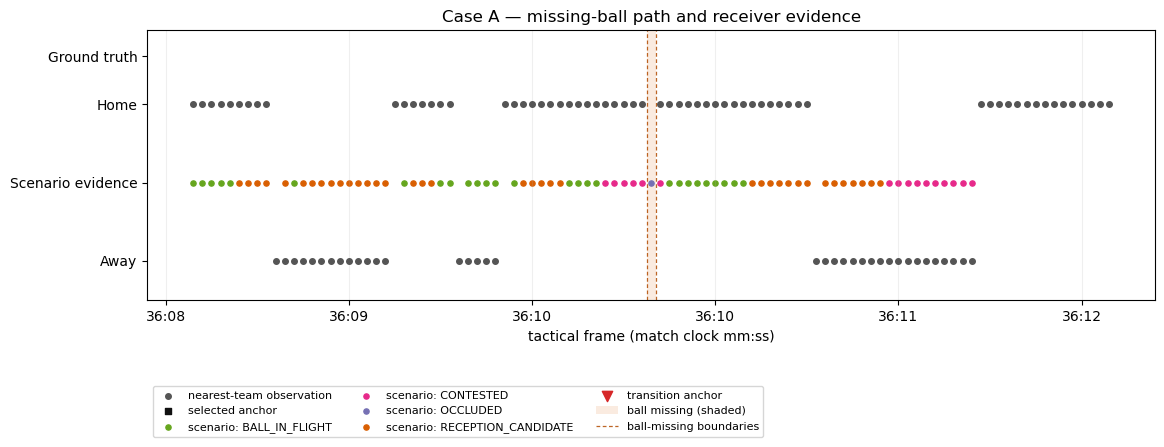

In [2]:
window = case_windows['case_a_missing_ball']
if window is None:
    print('No missing-ball case found.')
else:
    fig, ax = plot_timeline_window(features, *window, ground_truth=gt_by_frame)
    ax.set_title('Case A — missing-ball path and receiver evidence')
    plt.show()

## Case B — short touch or candidate handoff

The nearest player can change during a pass, deflection, or poor touch. We therefore combine proximity with a contact-like ball change, candidate arrival, pressure, and short forward persistence. This opens a local transition hypothesis; it does not globally rewrite `CONTESTED` into `H` or `A`.

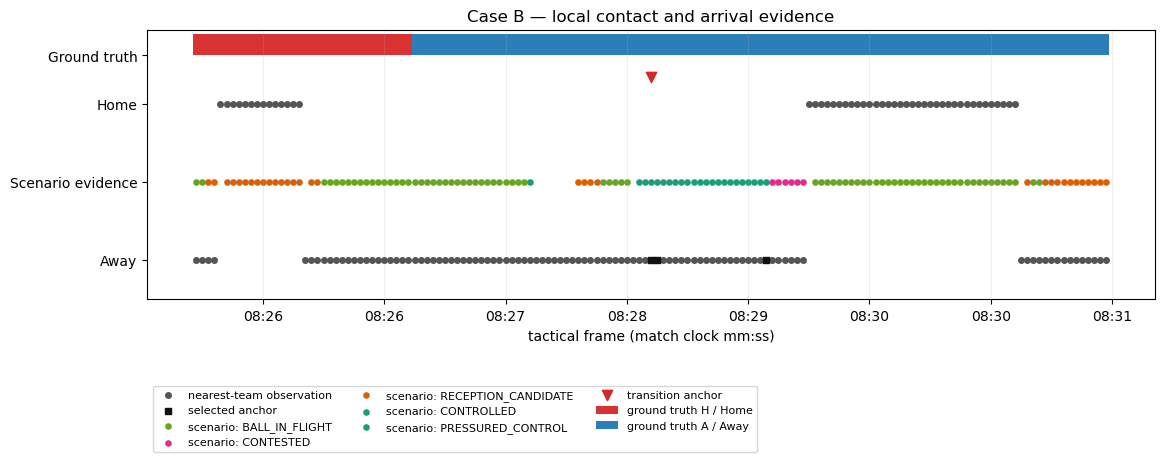

In [3]:
window = case_windows['case_b_candidate_transition']
if window is None:
    print('No candidate transition case found.')
else:
    fig, ax = plot_timeline_window(features, *window, ground_truth=gt_by_frame)
    ax.set_title('Case B — local contact and arrival evidence')
    plt.show()

## Case C — observed turnover

A public H/A change is used only to audit the evidence around an event. Looking backward shows the previous control and approach; looking forward shows whether the candidate receiver actually controls the ball. This is why transition decisions are interval-based rather than nearest-player decisions.

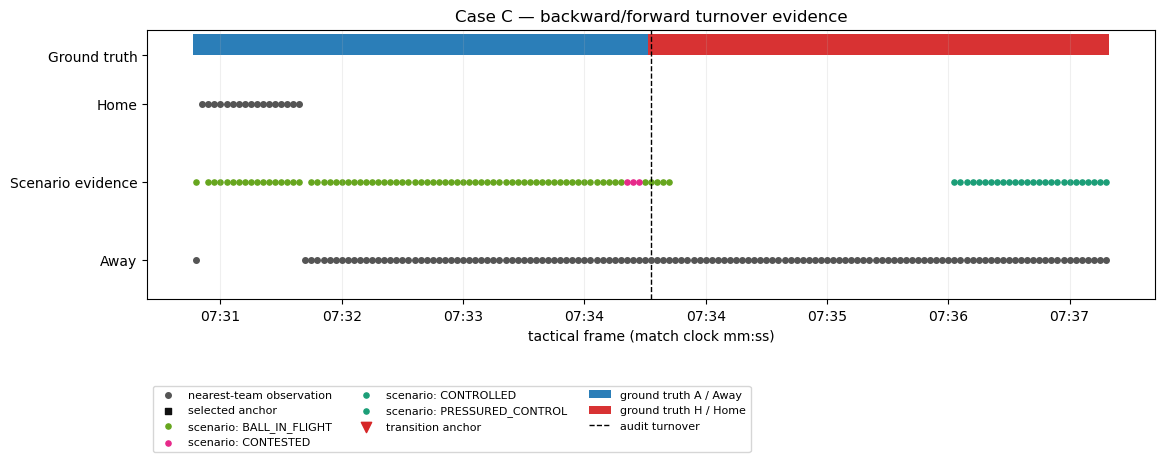

In [4]:
gt_known = gt_by_frame.dropna() if gt_by_frame is not None else pd.Series(dtype=object)
gt_h_a = gt_known[gt_known.isin(['H', 'A'])]
gt_switches = gt_h_a.index[(gt_h_a != gt_h_a.shift()) & gt_h_a.shift().isin(['H', 'A'])]
if len(gt_switches) == 0:
    print('No public H/A turnover available.')
else:
    frame = int(gt_switches[0])
    left = max(int(features['frame'].min()), frame - 75)
    right = min(int(features['frame'].max()), frame + 75)
    fig, ax = plot_timeline_window(features, left, right, ground_truth=gt_by_frame)
    ax.axvline(frame, color='black', linestyle='--', linewidth=1, label='audit turnover')
    ax.set_title('Case C — backward/forward turnover evidence')
    ax.legend(loc='upper left', bbox_to_anchor=(0, -0.30), ncol=3, fontsize=8)
    plt.show()

## Case D — long-ball outcomes

A launch supports continuity for the launching team during flight, but it does not prove who wins the landing. We therefore keep **multiple local kick candidates and control/touch candidates**: every candidate has its own departure, local low-speed boundary, and travelled distance. A later kick can start a new episode after a touch; it must not extend the previous flight.

A distance of at least 20 metres plus sharp departure acceleration is the long-ball criterion. A shorter kick can still be useful evidence of a heavy touch or handoff, but it is labelled a kick candidate rather than upgraded to a long ball. Local speed minima—not a global minimum—show possible control points.

**D1 reading.** The first kick impulse is just before 43:16. Speed then falls to a local trough around 43:17, where the reception candidate is consistent with a heavy touch; the ball then moves toward the opposition. The contest beginning around 43:19 is shown as a separate downstream contested episode, not as extra travel from the first kick. This is evidence for a touch followed by a possible turnover, not proof that the later contest was caused directly by the original kick.

**D2 reading.** The kick travels into a crowded area, then the ball remains contested. The plot continues through the end of that contest and shows the first subsequent scenario/possession evidence when available; if no stable change follows, the result remains unresolved.

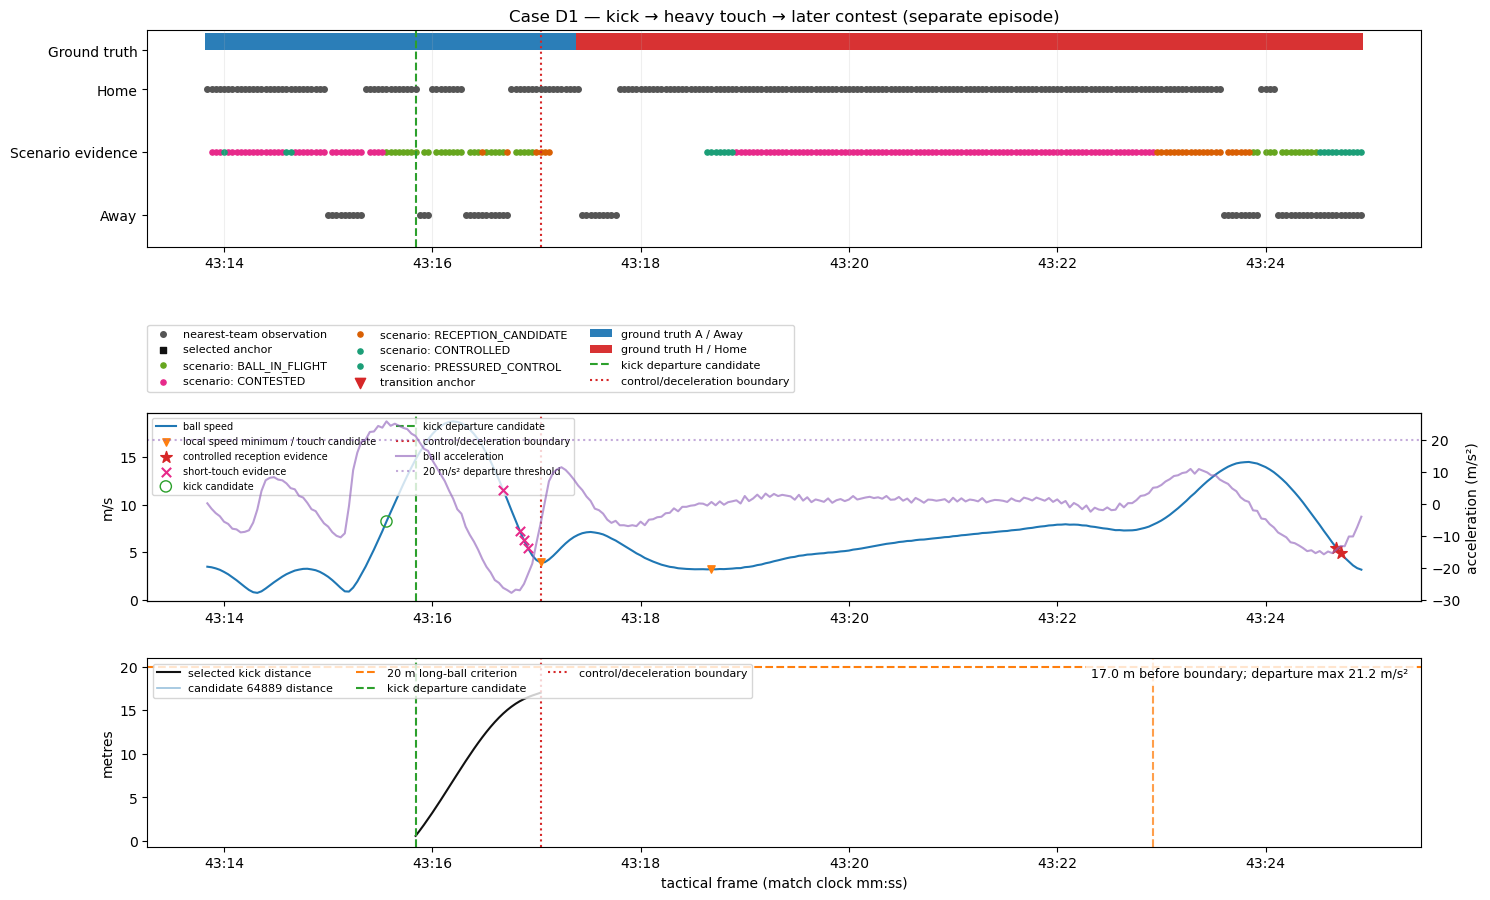

,case,event,frame,distance_m,evidence
1,case_d1_long_ball_turnover,kick candidate,64889,0.329631,sharp acceleration
0,case_d1_long_ball_turnover,selected kick candidate,64896,17.010291,kick boundary
2,case_d1_long_ball_turnover,control/touch candidate,64917,NaN,"local minimum, reception, or short-touch signal"
3,case_d1_long_ball_turnover,control/touch candidate,64921,NaN,"local minimum, reception, or short-touch signal"
4,case_d1_long_ball_turnover,control/touch candidate,64922,NaN,"local minimum, reception, or short-touch signal"
5,case_d1_long_ball_turnover,control/touch candidate,64923,NaN,"local minimum, reception, or short-touch signal"
6,case_d1_long_ball_turnover,control/touch candidate,64926,NaN,"local minimum, reception, or short-touch signal"
7,case_d1_long_ball_turnover,control/touch candidate,64967,NaN,"local minimum, reception, or short-touch signal"
8,case_d1_long_ball_turnover,control/touch candidate,65117,NaN,"local minimum, reception, or short-touch signal"
9,case_d1_long_ball_turnover,control/touch candidate,65118,NaN,"local minimum, reception, or short-touch signal"


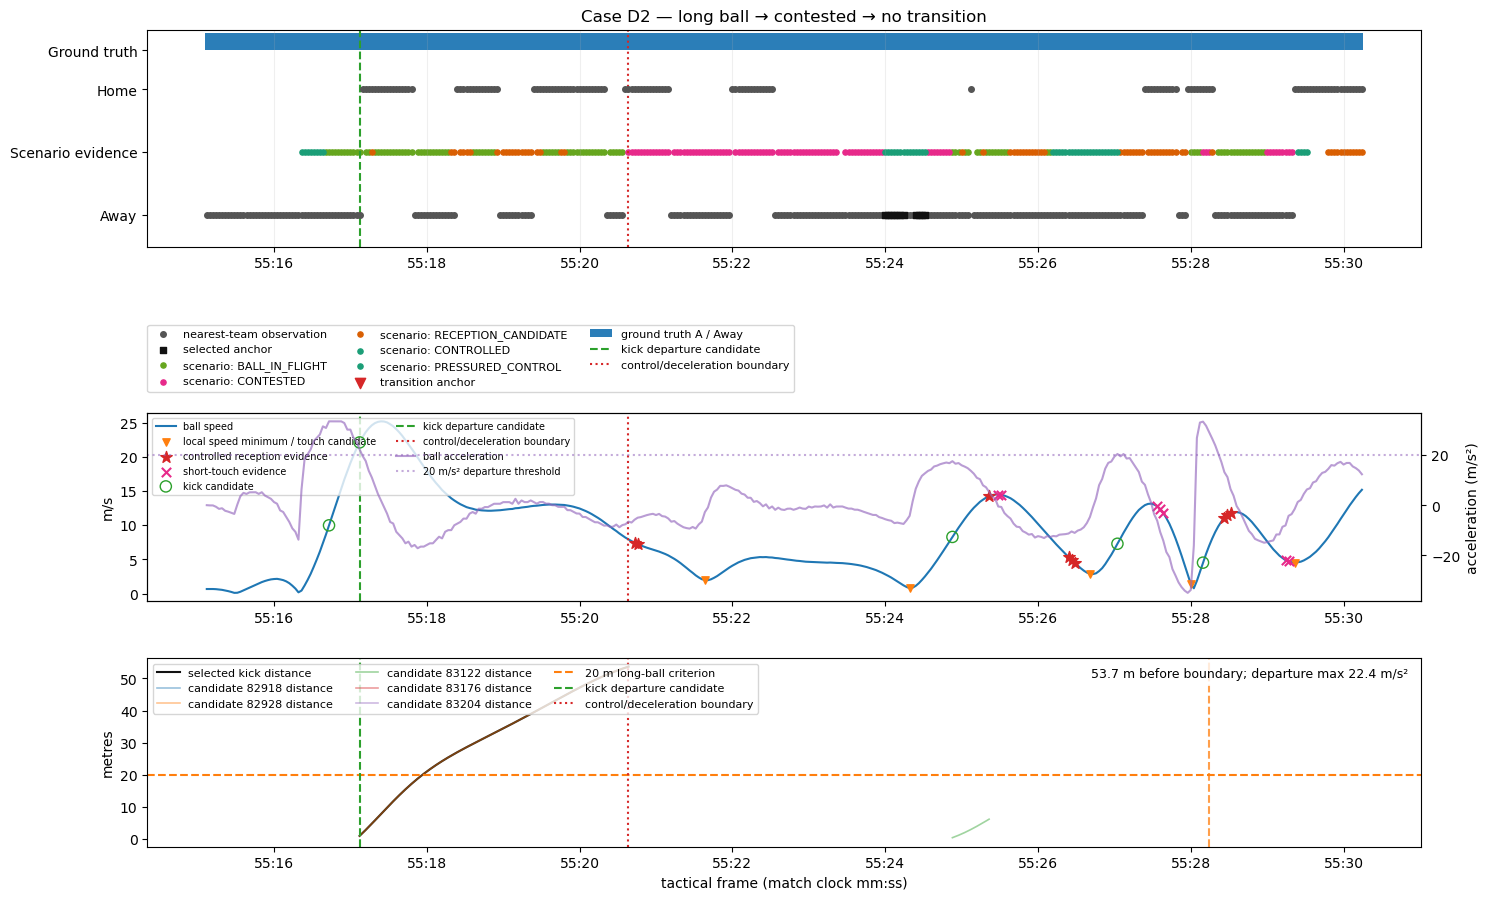

,case,event,frame,distance_m,evidence
1,case_d2_long_ball_no_turnover,kick candidate,82918,0.399220,sharp acceleration
2,case_d2_long_ball_no_turnover,kick candidate,82928,53.691910,sharp acceleration
0,case_d2_long_ball_no_turnover,selected kick candidate,82928,53.691910,long_ball boundary
6,case_d2_long_ball_no_turnover,control/touch candidate,83018,NaN,"local minimum, reception, or short-touch signal"
7,case_d2_long_ball_no_turnover,control/touch candidate,83019,NaN,"local minimum, reception, or short-touch signal"
8,case_d2_long_ball_no_turnover,control/touch candidate,83041,NaN,"local minimum, reception, or short-touch signal"
9,case_d2_long_ball_no_turnover,control/touch candidate,83108,NaN,"local minimum, reception, or short-touch signal"
3,case_d2_long_ball_no_turnover,kick candidate,83122,6.099522,sharp acceleration
10,case_d2_long_ball_no_turnover,control/touch candidate,83134,NaN,"local minimum, reception, or short-touch signal"
11,case_d2_long_ball_no_turnover,control/touch candidate,83137,NaN,"local minimum, reception, or short-touch signal"


retrospective long-ball cases: {'case_d1_long_ball_turnover': (64846, 65123), 'case_d2_long_ball_no_turnover': (82878, 83256)}


,case,episode_id,start_position,end_position,start,end,distance_m,departure_acceleration,candidate_kind,prior,later,contested_frames,direct_contested_frames,later_contested_frames,transition_frames,control_frames,short_touch_frames,reception_frames,contested_end
0,case_d1_long_ball_turnover,1269,64896,64926,64896,64926,17.010291,21.158934,kick,A,H,0,0,79,4,0,6,0,65073
1,case_d2_long_ball_no_turnover,1536,82928,83016,82928,83016,53.691910,22.393465,long_ball,A,A,25,25,63,3,3,2,0,83206


In [5]:
audit_gt = insight_gt_by_frame.dropna() if insight_gt_by_frame is not None else pd.Series(dtype=object)
# Keep the canonical kick episodes, then inspect their local candidate
# boundaries. One episode is not one possession event: a touch can end
# one kick and a later acceleration can start another.
long_ball_distance_threshold_m = 20.0
episode_ids = pd.to_numeric(features.get('kick_episode_id', pd.Series(-1, index=features.index)), errors='coerce').fillna(-1).to_numpy(int)
episode_ends = features.get('kick_episode_end', pd.Series(False, index=features.index)).fillna(False).to_numpy(bool)
episode_starts = features.get('kick_episode_start', pd.Series(False, index=features.index)).fillna(False).to_numpy(bool)
episode_distances = pd.to_numeric(features.get('kick_episode_distance_m', pd.Series(0.0, index=features.index)), errors='coerce').fillna(0.0).to_numpy(float)
episode_acceleration = pd.to_numeric(features.get('ball_acceleration_mps2', pd.Series(np.nan, index=features.index)), errors='coerce').to_numpy(float)
long_ball_acceleration_threshold = float(rules['bridging']['long_ball_acceleration_mps2'])
departure_window_frames = 8
d1_reference_frame = 64896  # observed impulse just before 43:16
outcome_audit_delay_frames = 10  # allow the touch to persist before auditing H/A
local_min_window = int(rules['reception_signal']['local_min_window_frames'])
control_speed_threshold = float(rules['anchors']['local_control_speed_max_mps'])
long_signal = np.zeros(len(features), dtype=bool)
long_episode_distances = {}
long_episode_departure_accelerations = {}
kick_candidate_records = []
for episode_id in sorted(set(episode_ids) - {-1}):
    positions = np.flatnonzero(episode_ids == episode_id)
    end_positions = positions[episode_ends[positions]]
    if not end_positions.size:
        continue
    end_position = int(end_positions[-1])
    start_positions = positions[episode_starts[positions]]
    start_position = int(start_positions[0]) if start_positions.size else int(positions[0])
    episode_speed = pd.to_numeric(features.iloc[positions].get('ball_speed_derived_mps', pd.Series(np.nan, index=positions)), errors='coerce')
    smoothed_episode_speed = episode_speed.interpolate(limit_direction='both').rolling(3, center=True, min_periods=1).median()
    local_stop_positions, _ = find_peaks(-smoothed_episode_speed.to_numpy(float), distance=local_min_window, prominence=0.75)
    local_stop_positions = [int(positions[position]) for position in local_stop_positions if int(positions[position]) >= start_position + local_min_window and smoothed_episode_speed.iloc[position] <= control_speed_threshold]
    if local_stop_positions:
        end_position = local_stop_positions[0]
    scenario_values = features.get('scenario_context', pd.Series('', index=features.index)).fillna('').astype(str).to_numpy()
    contested_positions = positions[(positions >= start_position + local_min_window) & (scenario_values[positions] == 'CONTESTED')]
    contested_stop = None
    for contested_position in contested_positions:
        position_after = min(len(features), int(contested_position) + 3)
        if np.sum(scenario_values[int(contested_position):position_after] == 'CONTESTED') >= 3:
            contested_stop = int(contested_position)
            break
    if contested_stop is not None:
        end_position = min(end_position, contested_stop)
    distance_m = float(episode_distances[end_position])
    departure_slice = episode_acceleration[start_position:min(len(features), start_position + departure_window_frames)]
    departure_acceleration = float(np.nanmax(departure_slice)) if np.isfinite(departure_slice).any() else 0.0
    if distance_m >= 10.0 and departure_acceleration >= long_ball_acceleration_threshold:
        kick_candidate_records.append({
            'episode_id': int(episode_id),
            'start_position': start_position,
            'end_position': end_position,
            'start': int(features.iloc[start_position]['frame']),
            'end': int(features.iloc[end_position]['frame']),
            'distance_m': distance_m,
            'departure_acceleration': departure_acceleration,
            'candidate_kind': 'long_ball' if distance_m >= long_ball_distance_threshold_m else 'kick',
        })
    if distance_m >= long_ball_distance_threshold_m and departure_acceleration >= long_ball_acceleration_threshold:
        flight_positions = positions[positions <= end_position]
        long_signal[flight_positions] = True
        long_episode_distances[episode_id] = distance_m
        long_episode_departure_accelerations[episode_id] = departure_acceleration
long_case_candidates = {'turnover': [], 'no_turnover': []}
for candidate in kick_candidate_records:
    flight_start, flight_end = candidate['start'], candidate['end']
    before = audit_gt.loc[audit_gt.index < flight_start]
    after = audit_gt.loc[audit_gt.index > flight_end + outcome_audit_delay_frames]
    if before.empty or after.empty:
        continue
    prior, later = before.iloc[-1], after.iloc[0]
    if prior not in ['H', 'A'] or later not in ['H', 'A']:
        continue
    outcome_key = 'turnover' if prior != later else 'no_turnover'
    landing_window = features.loc[features['frame'].between(flight_end - 25, flight_end + 25)]
    evidence_window = features.loc[features['frame'].between(flight_end - 25, flight_end + 125)]
    contested_frames = int(landing_window.get('scenario_context', pd.Series(dtype=object)).eq('CONTESTED').sum())
    transition_frames = int(landing_window.get('scenario_context', pd.Series(dtype=object)).eq('TRANSITION_CANDIDATE').sum())
    control_frames = int(evidence_window.get('controlled_reception_signal', pd.Series(False, index=evidence_window.index)).fillna(False).sum())
    short_touch_frames = int(evidence_window.get('short_touch_signal', pd.Series(False, index=evidence_window.index)).fillna(False).sum())
    reception_frames = int(evidence_window.get('genuine_reception_anchor', pd.Series(False, index=evidence_window.index)).fillna(False).sum())
    direct_contested_frames = int(features.loc[features['frame'].between(flight_end, flight_end + 25), 'scenario_context'].eq('CONTESTED').sum())
    later_contested_frames = int(features.loc[features['frame'].between(flight_end + 25, flight_end + 125), 'scenario_context'].eq('CONTESTED').sum())
    # A shorter kick with a clear touch is useful for D1, but is not
    # silently promoted to a 20 m long ball. D2 requires direct contest
    # evidence around the flight boundary.
    keep_candidate = (candidate['candidate_kind'] == 'long_ball' and (direct_contested_frames or later_contested_frames)) or (candidate['candidate_kind'] == 'kick' and outcome_key == 'turnover' and (short_touch_frames or control_frames or later_contested_frames))
    if keep_candidate:
        long_case_candidates[outcome_key].append({
            **candidate,
            'prior': prior,
            'later': later,
            'contested_frames': contested_frames,
            'direct_contested_frames': direct_contested_frames,
            'later_contested_frames': later_contested_frames,
            'transition_frames': transition_frames,
            'control_frames': control_frames,
            'short_touch_frames': short_touch_frames,
            'reception_frames': reception_frames,
            'distance_m': candidate['distance_m'],
            'departure_acceleration': candidate['departure_acceleration'],
        })
long_cases = {}
long_case_distances = {}
long_case_flights = {}
long_case_episode_ids = {}
long_case_evidence = {}
for outcome_key, candidates in long_case_candidates.items():
    if not candidates:
        continue
    control_pool = [row for row in candidates if row['control_frames'] > 0]
    touch_pool = [row for row in candidates if row['short_touch_frames'] > 0]
    candidate_pool = control_pool or touch_pool or candidates
    best = max(candidate_pool, key=lambda row: (
        row['direct_contested_frames'] * 4 + row['later_contested_frames'] * 2
        + row['control_frames'] * 3 + row['short_touch_frames'] * 3
        + row['transition_frames'] * 2, row['distance_m']))
    if outcome_key == 'turnover':
        observed_d1 = [row for row in candidate_pool if abs(row['start'] - d1_reference_frame) <= 100]
        if observed_d1:
            best = min(observed_d1, key=lambda row: abs(row['start'] - d1_reference_frame))
    key = 'case_d1_long_ball_turnover' if outcome_key == 'turnover' else 'case_d2_long_ball_no_turnover'
    forward_contested = features.loc[(features['frame'] >= best['end']) & (features['frame'] <= best['end'] + 200) & features['scenario_context'].eq('CONTESTED'), 'frame'].to_numpy(int)
    contested_end = int(forward_contested[-1]) if len(forward_contested) else None
    context_end = contested_end + 50 if contested_end is not None else best['end'] + 75
    long_cases[key] = (max(int(features['frame'].min()), best['start'] - 50), min(int(features['frame'].max()), context_end))
    long_case_distances[key] = best['distance_m']
    long_case_flights[key] = (best['start'], best['end'])
    long_case_episode_ids[key] = best['episode_id']
    best['contested_end'] = contested_end
    long_case_evidence[key] = best

for key, (left, right) in long_cases.items():
    flight_start, flight_end = long_case_flights[key]
    episode_id = long_case_episode_ids[key]
    plot_features = features.loc[features['frame'].between(left, right)].copy()
    plot_speed = pd.to_numeric(plot_features.get('ball_speed_derived_mps', pd.Series(np.nan, index=plot_features.index)), errors='coerce')
    plot_acceleration = pd.to_numeric(plot_features.get('ball_acceleration_mps2', pd.Series(np.nan, index=plot_features.index)), errors='coerce')
    plot_deceleration = pd.to_numeric(plot_features.get('reception_ball_deceleration_mps', pd.Series(np.nan, index=plot_features.index)), errors='coerce')
    plot_episode_id = pd.to_numeric(plot_features.get('kick_episode_id', pd.Series(-1, index=plot_features.index)), errors='coerce')
    plot_distance = pd.to_numeric(plot_features.get('kick_episode_distance_m', pd.Series(np.nan, index=plot_features.index)), errors='coerce').where(plot_episode_id.eq(episode_id) & plot_features['frame'].le(flight_end))
    evidence = long_case_evidence[key]
    post_flight = plot_features['frame'].ge(flight_end - local_min_window)
    smoothed_speed = plot_speed.interpolate(limit_direction='both').rolling(3, center=True, min_periods=1).median()
    local_min_positions, _ = find_peaks(-smoothed_speed.to_numpy(float), distance=local_min_window, prominence=0.75)
    local_speed_min = pd.Series(False, index=plot_features.index)
    local_speed_min.iloc[local_min_positions] = True
    local_speed_min &= post_flight & plot_speed.notna()
    control_signal = plot_features.get('controlled_reception_signal', pd.Series(False, index=plot_features.index)).fillna(False).astype(bool) | plot_features.get('genuine_reception_anchor', pd.Series(False, index=plot_features.index)).fillna(False).astype(bool)
    short_touch_signal = plot_features.get('short_touch_signal', pd.Series(False, index=plot_features.index)).fillna(False).astype(bool)
    control_candidates = control_signal & post_flight
    touch_candidates = short_touch_signal & post_flight
    if key == 'case_d1_long_ball_turnover':
        outcome = 'kick → heavy touch → later contest (separate episode)'
    else:
        outcome = 'long ball → contested → no transition'
    kick_start_mask = plot_features.get('kick_episode_start', pd.Series(False, index=plot_features.index)).fillna(False).astype(bool) & plot_acceleration.ge(long_ball_acceleration_threshold - 5.0)
    raw_kick_positions = np.flatnonzero(kick_start_mask.to_numpy())
    kick_positions = []
    for position in raw_kick_positions:
        if not kick_positions or int(plot_features.iloc[position]['frame']) - int(plot_features.iloc[kick_positions[-1]]['frame']) >= 10:
            kick_positions.append(int(position))
        elif plot_acceleration.iloc[position] > plot_acceleration.iloc[kick_positions[-1]]:
            kick_positions[-1] = int(position)
    kick_event_mask = pd.Series(False, index=plot_features.index)
    kick_event_mask.iloc[kick_positions] = True
    event_rows = []
    event_rows.append({'case': key, 'event': 'selected kick candidate', 'frame': flight_start, 'distance_m': evidence['distance_m'], 'evidence': evidence['candidate_kind'] + ' boundary'})
    for position in kick_positions:
        candidate_frame = int(plot_features.iloc[position]['frame'])
        candidate_episode = int(plot_episode_id.iloc[position])
        candidate_distance = pd.to_numeric(plot_features.loc[plot_episode_id.eq(candidate_episode), 'kick_episode_distance_m'], errors='coerce')
        if candidate_episode == episode_id:
            candidate_distance = candidate_distance.where(plot_features.loc[candidate_distance.index, 'frame'].le(flight_end))
        event_rows.append({'case': key, 'event': 'kick candidate', 'frame': candidate_frame, 'distance_m': float(candidate_distance.max()) if candidate_distance.notna().any() else np.nan, 'evidence': 'sharp acceleration'})
    for frame in plot_features.loc[(local_speed_min | control_candidates | touch_candidates), 'frame'].astype(int).drop_duplicates():
        event_rows.append({'case': key, 'event': 'control/touch candidate', 'frame': int(frame), 'distance_m': np.nan, 'evidence': 'local minimum, reception, or short-touch signal'})
    fig = plt.figure(figsize=(14, 9.5), constrained_layout=False)
    grid = fig.add_gridspec(4, 1, height_ratios=[1.15, 0.28, 1, 1], hspace=0.35)
    timeline_ax = fig.add_subplot(grid[0])
    speed_ax = fig.add_subplot(grid[2], sharex=timeline_ax)
    distance_ax = fig.add_subplot(grid[3], sharex=timeline_ax)
    plot_timeline_window(features, left, right, ground_truth=insight_gt_by_frame, ax=timeline_ax)
    timeline_ax.set_title(f"{key.split('_long_ball_')[0].replace('_', ' ').title()} — {outcome}")
    timeline_ax.axvline(flight_start, color='#2ca02c', linestyle='--', label='kick departure candidate')
    timeline_ax.axvline(flight_end, color='#d62728', linestyle=':', label='control/deceleration boundary')
    timeline_ax.set_xlabel('')
    timeline_handles, timeline_labels = timeline_ax.get_legend_handles_labels()
    timeline_ax.legend(timeline_handles, timeline_labels, loc='upper left', bbox_to_anchor=(0, -0.36), ncol=3, fontsize=8, borderaxespad=0.0)
    speed_ax.plot(plot_features['frame'], plot_speed, color='#1f77b4', label='ball speed')
    speed_accel_ax = speed_ax.twinx()
    speed_accel_ax.plot(plot_features['frame'], plot_acceleration, color='#9467bd', alpha=0.65, label='ball acceleration')
    speed_accel_ax.axhline(long_ball_acceleration_threshold, color='#9467bd', linestyle=':', alpha=0.55, label=f'{long_ball_acceleration_threshold:.0f} m/s² departure threshold')
    speed_accel_ax.set_ylabel('acceleration (m/s²)')
    speed_ax.scatter(plot_features.loc[local_speed_min, 'frame'], plot_speed.loc[local_speed_min], color='#ff7f0e', marker='v', s=28, zorder=5, label='local speed minimum / touch candidate')
    speed_ax.scatter(plot_features.loc[control_candidates, 'frame'], plot_speed.loc[control_candidates], color='#d62728', marker='*', s=75, zorder=6, label='controlled reception evidence')
    speed_ax.scatter(plot_features.loc[touch_candidates, 'frame'], plot_speed.loc[touch_candidates], color='#e7298a', marker='x', s=45, zorder=6, label='short-touch evidence')
    speed_ax.scatter(plot_features.loc[kick_event_mask, 'frame'], plot_speed.loc[kick_event_mask], color='#2ca02c', marker='o', facecolors='none', s=65, zorder=7, label='kick candidate')
    speed_ax.axvline(flight_start, color='#2ca02c', linestyle='--', label='kick departure candidate')
    speed_ax.axvline(flight_end, color='#d62728', linestyle=':', label='control/deceleration boundary')
    speed_ax.set_ylabel('m/s')
    speed_handles, speed_labels = speed_ax.get_legend_handles_labels()
    accel_handles, accel_labels = speed_accel_ax.get_legend_handles_labels()
    speed_ax.legend(speed_handles + accel_handles, speed_labels + accel_labels, loc='upper left', ncol=2, fontsize=7)
    distance_ax.plot(plot_features['frame'], plot_distance, color='#111111', label='selected kick distance')
    for position in kick_positions:
        candidate_episode = int(plot_episode_id.iloc[position])
        candidate_distance_trace = pd.to_numeric(plot_features.get('kick_episode_distance_m', pd.Series(np.nan, index=plot_features.index)), errors='coerce').where(plot_episode_id.eq(candidate_episode))
        if candidate_episode == episode_id:
            candidate_distance_trace = candidate_distance_trace.where(plot_features['frame'].le(flight_end))
        distance_ax.plot(plot_features['frame'], candidate_distance_trace, alpha=0.45, linewidth=1.2, label=f'candidate {int(plot_features.iloc[position]["frame"])} distance')
    distance_ax.axhline(long_ball_distance_threshold_m, color='#ff7f0e', linestyle='--', label='20 m long-ball criterion')
    distance_ax.axvline(flight_start, color='#2ca02c', linestyle='--', label='kick departure candidate')
    distance_ax.axvline(flight_end, color='#d62728', linestyle=':', label='control/deceleration boundary')
    distance_ax.set_ylabel('metres')
    distance_ax.set_xlabel('tactical frame (video time MM:SS)')
    _configure_match_clock_axis(distance_ax, plot_features)
    distance_ax.legend(loc='upper left', ncol=3, fontsize=8)
    if evidence.get('contested_end') is not None:
        distance_ax.axvline(evidence['contested_end'], color='#ff7f0e', linestyle='--', alpha=0.75, label='end of visible contest')
    distance_ax.text(0.99, 0.95, f"{evidence['distance_m']:.1f} m before boundary; departure max {evidence['departure_acceleration']:.1f} m/s²", transform=distance_ax.transAxes, ha='right', va='top', fontsize=9, bbox=dict(facecolor='white', alpha=0.8, edgecolor='none'))
    fig.subplots_adjust(left=0.07, right=0.98, top=0.96, bottom=0.10)
    plt.show()
    if event_rows:
        display(pd.DataFrame(event_rows).sort_values(['frame', 'event']))
print('retrospective long-ball cases:', long_cases)
display(pd.DataFrame([{'case': key, **long_case_evidence[key]} for key in long_cases]))

## Case evidence passed to the pipeline

The compact record keeps significant player paths, arrival/pressure summaries, and frame-level scenario context. The transition layer then tests `KEEP_CURRENT`, `SWITCH_TO_H`, `SWITCH_TO_A`, `ENTER_D`, restart hypotheses, and `CONTESTED`. The interval resolver decides when evidence is strong enough to change the final label.

In [6]:
scenario_evidence = {}
for name, bounds in {**case_windows, **long_cases}.items():
    if bounds is None:
        continue
    evidence = build_scenario_evidence(features, *bounds, team_by_slot, radius_m=12.0)
    scenario_evidence[name] = {
        'summary': evidence['summary'],
        'players': evidence['summary_table'].to_dict('records'),
        'frames': evidence['trajectory_table'].replace({np.nan: None}).to_dict('records'),
    }
trajectory_path = ROOT / 'cache' / 'scenario_case_player_trajectories.json'
trajectory_path.parent.mkdir(parents=True, exist_ok=True)
trajectory_path.write_text(json.dumps(scenario_evidence, indent=2, default=str), encoding='utf-8')
print(f'saved case evidence: {trajectory_path}')

saved case evidence: /Users/luke/Desktop/barca-hack-repo-staging/cache/scenario_case_player_trajectories.json


## Findings

- Closest-player evidence proposes a receiver; it does not prove control.
- Missing-ball and long-ball intervals need path agreement plus player arrival and post-touch persistence.
- A contested episode should remain unresolved rather than being forced into a team label.
- Restart context protects `D`, while physical activation and control evidence determine when live play resumes.
- These cases motivate the conservative hypothesis-test resolver used by the full-match pipeline.